In [37]:
from pathlib import Path
import pandas as pd
import numpy as np
from joblib import Parallel, delayed
from collections import defaultdict
import pickle
import matplotlib.pyplot as plt

In [58]:
ROOT = Path().cwd()
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
FANTOM = DATA / "fantom_cat"
FANTOM_INITIAL = DATA_INITIAL / "fantom_cat"
PREPROCESSING = Path("../preprocessing")

MATRICES = PREPROCESSING / "matrices"
IPS_MATRICES = MATRICES / "ips_matrices"
FIBRO_MATRICES = MATRICES / "fibro_matrices"

INFO = PREPROCESSING / "info"
IPS_INFO = INFO / "ips_info"
FIBRO_INFO = INFO / "fibro_info"

JACCARD = PREPROCESSING / "jaccard"
IPS_JACCARD = JACCARD / "ips_jaccard"
FIBRO_JACCARD = JACCARD / "fibro_jaccard"

RESULTS = Path("../results")
JACCARD_RESULTS = RESULTS / "jaccard"

In [5]:
def jaccard_index(to_matrice):
    matrice = np.load(to_matrice)
    jaccard_value = matrice[0].sum() / (~matrice[3]).sum()
    return jaccard_value

In [52]:
def reshape_df(df):
    df['combination'] = df['corr_sign'] + '_' + df['up_or_down_expr']
    # Создание сводной таблицы
    pivot_df = df.pivot_table(index=['hm', 'lnc_ens', 'aso'], 
                              columns='combination', 
                              values='jaccard', 
                              aggfunc='mean').reset_index()
    pivot_df = pivot_df.rename(columns={"minus_down":"jaccard-minus_down", "minus_up":"jaccard-minus_up", "plus_down":"jaccard-plus_down", "plus_up":"jaccard-plus_up"})
    # Заполнение NaN значений нулями или другими значениями по необходимости
    pivot_df = pivot_df.fillna(0)
    return pivot_df

mm => er => md
mp => ea => mu
pm => wa => pd
pp => wr => pu

In [53]:
def job(hm, exp):
    jaccard_indexes = []
    lncrna = []
    aso = []
    corr_sign = []
    up_or_down_expr = []
    for to_matrice in (MATRICES / f"{exp}_matrices" / hm).glob('*'):
        jaccard_indexes.append(jaccard_index(to_matrice))
        lncrna.append(to_matrice.name.split("-")[0])
        aso.append(to_matrice.name.split("-")[1])
        corr_sign.append(to_matrice.name.split("-")[2])
        up_or_down_expr.append(to_matrice.name.split("-")[3])
    df = pd.DataFrame({"hm": [hm for i in range(len(jaccard_indexes))],
                       "lnc_ens": lncrna,
                       "aso": aso,
                       "jaccard": jaccard_indexes,
                       "corr_sign": corr_sign,
                       "up_or_down_expr": up_or_down_expr
                      })
    df = reshape_df(df)
    to_save = JACCARD / f"{exp}_jaccard"  / f"{hm}.tsv"
    if to_save.exists():
        print(f"Skipped: {exp} {hm}")
        return
    to_save.parent.mkdir(exist_ok=True, parents=True)
    df.to_csv(to_save, sep="\t", index=False)

In [54]:
list_of_hm = ['H3K27ac', 'H3K27me3', 'H3K36me3', 'H3K4me1', 'H3K4me2', 'H3K4me3', 'H3K79me2', 'H3K9ac', 'H3K9me3', 'H4K20me1', 'methylation']
to_save = FANTOM / "fantom_lv2-hg38-ens_name-mapping.tsv.gz"
fantom_lv2_mapping_hg38 = pd.read_csv(to_save, sep="\t", index_col="geneID_without_v")
fantom_lv2_mapping_hg38.head()

,geneName
geneID_without_v,
CATG00000000002,CATG00000000002.1
CATG00000000003,CATG00000000003.1
CATG00000000004,CATG00000000004.1
CATG00000000005,CATG00000000005.1
CATG00000000006,CATG00000000006.1


In [55]:
fantom_lv2_mapping_hg38.shape

(123997, 1)

In [56]:
with Parallel(n_jobs=-1) as pool:
    chunks = pool(
        delayed(job)(hm=hm, exp=exp)
        for exp in ["fibro", "ips"]
        for hm in list_of_hm)

In [59]:
jaccard_results_by_exp = {}
usecols=["hm", "lnc_ens", "aso", "jaccard-minus_down", "jaccard-minus_up", "jaccard-plus_down", "jaccard-plus_up"]
for exp in ["fibro", "ips"]:
    jaccard_results = [pd.read_csv(to_df, usecols=usecols, sep="\t") for to_df in (JACCARD / f"{exp}_jaccard").glob("*.tsv")]
    jaccard_results = pd.concat(jaccard_results).reset_index(drop=True)

    jaccard_results = jaccard_results.rename(columns={"jaccard-minus_down":"jaccard-er", "jaccard-minus_up":"jaccard-ea", "jaccard-plus_down":"jaccard-wa", "jaccard-plus_up":"jaccard-wr"})
    jaccard_results["lnc"] = jaccard_results["lnc_ens"].apply(lambda x: fantom_lv2_mapping_hg38.loc[x, "geneName"])
    to_save = JACCARD_RESULTS / f"{exp}-jaccard-concat.tsv"
    jaccard_results.to_csv(to_save, sep="\t", index=False)
    jaccard_results_by_exp[exp] = jaccard_results

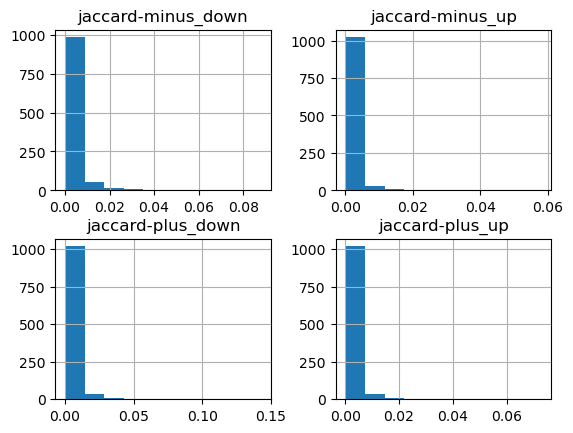

In [42]:
exp = "fibro"
jaccard_fibro = pd.concat([pd.read_csv(to_file, sep="\t") for to_file in (JACCARD / f"{exp}_jaccard").glob("*.tsv")])
jaccard_fibro[["jaccard-minus_down","jaccard-minus_up","jaccard-plus_down","jaccard-plus_up"]].hist()
plt.show()

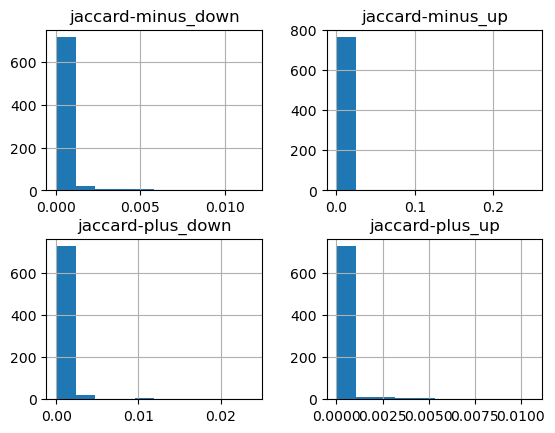

In [40]:
exp = "ips"
jaccard_fibro = pd.concat([pd.read_csv(to_file, sep="\t") for to_file in (JACCARD / f"{exp}_jaccard").glob("*.tsv")])
jaccard_fibro[["jaccard-minus_down","jaccard-minus_up","jaccard-plus_down","jaccard-plus_up"]].hist()
plt.show()